# Practical Application III: Comparing Classifiers
**Assignment 17.1 | Author: Hari Raghavendra**

Can pre-call information help a Portuguese bank prioritize contacts likely to subscribe to a term deposit? This notebook compares **k-nearest neighbors, logistic regression, decision trees and support vector machines** using the supplied UCI Bank Marketing data.

The analysis follows the assignment's Problems 1–11. The default comparison uses only seven client-information fields; the improvement stage adds historical, economic and planned-contact information. All reported scores are computed by this notebook. Model selection uses training cross-validation; the final holdout is reserved for evaluation.


## Problem 1: Understanding the Data
The supplied paper, *Using Data Mining for Bank Direct Marketing: An Application of the CRISP-DM Methodology* (Moro, Laureano and Cortez, 2011), states in **Materials and Methods, page 2**, that the original collection covers **17 campaigns**, May 2008–November 2010, with 79,354 contacts. Its later cleaning stages produce other sample sizes, including 45,211 records.

Our supplied **bank-additional-full.csv** contains 41,188 rows and 20 predictors plus the target. Its accompanying names file links this enriched public release to Moro, Cortez and Rita (2014). These are related sources, not identical analytical samples; do not copy the paper's sample counts or reported model scores into our results.

Sources: [provided paper](CRISP-DM-BANK.pdf), [data dictionary](data/bank-additional-names.txt), [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing), [2014 article DOI](https://doi.org/10.1016/j.dss.2014.03.001).


In [1]:
from pathlib import Path
from time import perf_counter
import json
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from scipy.stats import norm
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, average_precision_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay)

SEED = 42
DATA_PATH = Path('data/bank-additional-full.csv')
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 15)
print({'Python': platform.python_version(), 'pandas': pd.__version__,
       'scikit-learn': sklearn.__version__, 'seed': SEED})


{'Python': '3.12.14', 'pandas': '2.2.3', 'scikit-learn': '1.8.0', 'seed': 42}


## Problem 2: Read in the Data
The full CSV uses semicolons as separators. The smaller `bank-additional.csv` is a random 10% sample of the full file, not independent test data; it is deliberately not concatenated or used as a holdout.


In [2]:
bank_raw = pd.read_csv(DATA_PATH, sep=';')
assert bank_raw.shape == (41188, 21), 'Unexpected input file: check the data source.'
print(f'Raw observations: {len(bank_raw):,}; columns: {bank_raw.shape[1]}')
display(bank_raw.head(3))
display(bank_raw['y'].value_counts().rename_axis('Subscribed').to_frame('Observations'))


Raw observations: 41,188; columns: 21


,age,job,marital,education,default,housing,loan,...,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


,Observations
Subscribed,
no,36548
yes,4640


## Problem 3: Understanding Features and Cleaning
- `unknown` is a missing-information category, not a literal null. Retain it explicitly instead of guessing credit/default status or deleting many observations.
- `pdays=999` means **no previous contact**, not a 999-day elapsed interval. Create an indicator and use missingness for the undefined interval in the improvement stage.
- Remove exact full-row duplicates as a conservative record-quality rule. Without client/contact IDs, identical records cannot be proven accidental; genuine repeated observations are possible. Do not collapse rows just because their demographic predictors match.
- Retain extreme but plausible ages and contact counts. An IQR flag is not sufficient evidence that a measurement is invalid.
- **Exclude `duration`** from every model. It is only known after the call. Also exclude `campaign` in the expanded model because its recorded total includes the current contact.
- Encoding, imputation and scaling are fitted inside pipelines using training folds only.


In [3]:
audit = pd.DataFrame({'dtype': bank_raw.dtypes.astype(str),
                      'null_count': bank_raw.isna().sum(),
                      'unknown_count': bank_raw.eq('unknown').sum()})
display(audit)
duplicate_count = int(bank_raw.duplicated().sum())
bank = bank_raw.drop_duplicates().copy().reset_index(drop=True)
assert bank['y'].isin(['yes', 'no']).all()
assert bank['age'].between(0, 120).all()
assert (bank[['campaign', 'previous', 'pdays']] >= 0).all().all()
print(f'Exact duplicate rows removed: {duplicate_count}; retained: {len(bank):,}')
print('Missing target values:', bank['y'].isna().sum())
num_cols = bank.select_dtypes(include='number').columns
q1, q3 = bank[num_cols].quantile(.25), bank[num_cols].quantile(.75)
iqr_flags = ((bank[num_cols] < q1 - 1.5*(q3-q1)) |
             (bank[num_cols] > q3 + 1.5*(q3-q1))).sum()
display(iqr_flags.rename('IQR flags: review, not deletion').to_frame())
print('The pdays sentinel is handled semantically, not removed as an outlier.')


Exact duplicate rows removed: 12; retained: 41,176
Missing target values: 0
The pdays sentinel is handled semantically, not removed as an outlier.


,dtype,null_count,unknown_count
age,int64,0,0
job,object,0,330
marital,object,0,80
education,object,0,1731
default,object,0,8597
housing,object,0,990
loan,object,0,990
contact,object,0,0
month,object,0,0
day_of_week,object,0,0


,"IQR flags: review, not deletion"
age,468
duration,2963
campaign,2406
pdays,1515
previous,5625
emp.var.rate,0
cons.price.idx,0
cons.conf.idx,446
euribor3m,0
nr.employed,0


## Problem 4: Business Objective and Evaluation Plan
**Objective:** rank eligible customers for outreach so the bank can capture more subscriptions within a fixed calling budget. The target is whether a term deposit was subscribed (`yes=1`). This is response prediction, not a causal estimate of the effect of calling.

**Primary selection metric: average precision (AP).** Subscribers are a minority, and the business needs useful ranking of likely responders. AP summarizes precision–recall performance across score thresholds; it is not trapezoidal PR-AUC. Compare it with the subscriber prevalence of the same evaluation set. Also report accuracy (explicitly requested), ROC-AUC, precision, recall, F1, balanced accuracy, fit time and top-20% precision/lift.

All models share one stratified 80/20 split and the same cross-validation folds. The random holdout is a coursework benchmark, **not a future-campaign simulation**: the source is ordered by date, full timestamps and campaign/client identifiers are unavailable, and repeat customers or shared economic periods may occur across folds. A deployment decision needs temporal/campaign-separated validation and current data. EDA below uses only the training partition.


In [4]:
target = bank['y'].eq('yes').astype(int)
train_idx, test_idx = train_test_split(bank.index, test_size=.20,
    stratify=target, random_state=SEED)
train_bank = bank.loc[train_idx].copy()
test_bank = bank.loc[test_idx].copy()
y_train = target.loc[train_idx]
y_test = target.loc[test_idx]
assert set(train_idx).isdisjoint(test_idx)
print(f'Train: {len(train_idx):,}; test: {len(test_idx):,}')
print(f'Train subscription rate: {y_train.mean():.2%}; test: {y_test.mean():.2%}')


Train: 32,940; test: 8,236
Train subscription rate: 11.27%; test: 11.27%


### EDA: who subscribed in the training sample?
Plots describe observed associations. Occupation or age differences can reflect financial circumstances, campaign selection and other confounding factors; they are not evidence of differential causal benefit from outreach.


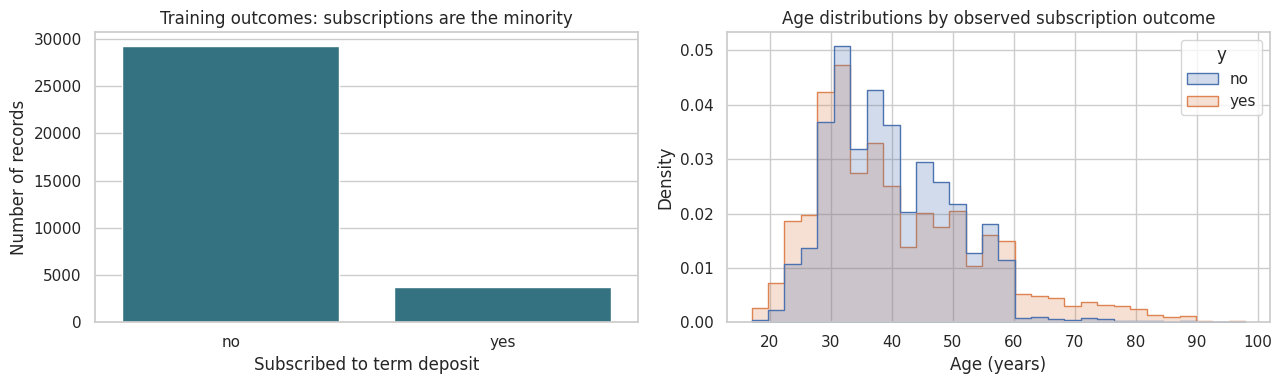

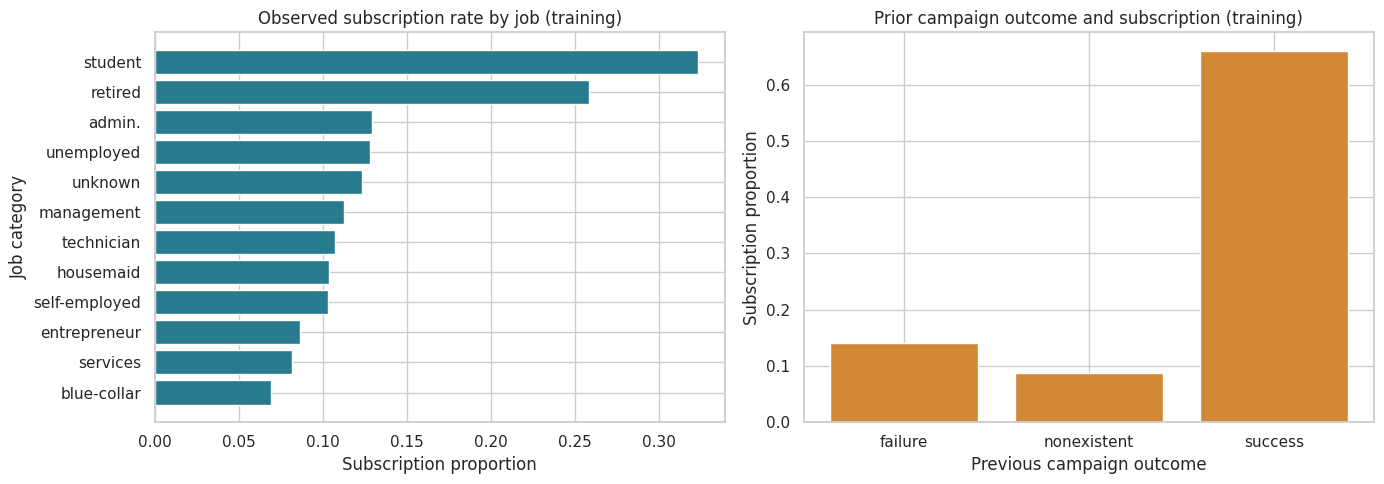

,records,subscribers,rate
job,,,
blue-collar,7440,516,0.069
services,3181,259,0.081
entrepreneur,1159,100,0.086
self-employed,1114,115,0.103
housemaid,859,89,0.104
technician,5420,582,0.107
management,2340,264,0.113
unknown,267,33,0.124
unemployed,812,104,0.128


,count,sum,mean
poutcome,,,
failure,3415,478,0.140
nonexistent,28431,2511,0.088
success,1094,722,0.660


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=train_bank, x='y', order=['no','yes'], ax=axes[0], color='#287a8e')
axes[0].set(title='Training outcomes: subscriptions are the minority',
            xlabel='Subscribed to term deposit', ylabel='Number of records')
sns.histplot(data=train_bank, x='age', hue='y', bins=30, stat='density',
             common_norm=False, element='step', ax=axes[1])
axes[1].set(title='Age distributions by observed subscription outcome',
            xlabel='Age (years)', ylabel='Density')
plt.tight_layout()
plt.show()
job_rates = train_bank.assign(subscribed=y_train).groupby('job')['subscribed'].agg(['count','sum','mean']).sort_values('mean')
fig, axes = plt.subplots(1,2,figsize=(14,5))
axes[0].barh(job_rates.index, job_rates['mean'], color='#287a8e')
axes[0].set(title='Observed subscription rate by job (training)',
            xlabel='Subscription proportion', ylabel='Job category')
previous_rates = train_bank.assign(subscribed=y_train).groupby('poutcome')['subscribed'].agg(['count','sum','mean'])
axes[1].bar(previous_rates.index, previous_rates['mean'],color='#d38836')
axes[1].set(title='Prior campaign outcome and subscription (training)',
            xlabel='Previous campaign outcome', ylabel='Subscription proportion')
plt.tight_layout()
plt.show()
display(job_rates.rename(columns={'count':'records','sum':'subscribers','mean':'rate'}).round(3))
display(previous_rates.round(3))


### Descriptive uncertainty
Wilson 95% intervals summarize binomial sampling uncertainty for observed group proportions. They do not correct for campaign selection, multiple comparisons, customer dependence or economic changes. Do not interpret them as causal effects or guaranteed future rates.


In [6]:
def wilson_interval(successes, total, confidence=.95):
    z = norm.ppf(1 - (1-confidence)/2)
    p = successes / total
    denom = 1 + z*z/total
    center = (p + z*z/(2*total))/denom
    half = z*np.sqrt(p*(1-p)/total + z*z/(4*total*total))/denom
    return center-half, center+half

rate_intervals = previous_rates.copy()
rate_intervals[['lower_95','upper_95']] = [wilson_interval(int(r['sum']),int(r['count'])) for _,r in rate_intervals.iterrows()]
display(rate_intervals.round(4))
rate_intervals.to_csv(RESULTS/'eda_prior_outcome_rates.csv')


,count,sum,mean,lower_95,upper_95
poutcome,,,,,
failure,3415,478,0.1400,0.1287,0.1520
nonexistent,28431,2511,0.0883,0.0851,0.0917
success,1094,722,0.6600,0.6314,0.6874


## Problem 5: Engineering Features (Client-Information Benchmark)
As requested, the initial comparison uses **age, job, marital, education, default, housing and loan** only. Age is standardized; categorical fields, including `unknown`, are one-hot encoded. No ordinal ranking is imposed on job or education. The same transformations are used for all four algorithms to keep the inputs consistent.


In [7]:
client_features = ['age','job','marital','education','default','housing','loan']

def build_preprocessor(frame):
    categorical = frame.select_dtypes(include=['object','category','bool']).columns.tolist()
    numeric = [c for c in frame.columns if c not in categorical]
    return ColumnTransformer([
        ('numeric', Pipeline([('impute',SimpleImputer(strategy='median')),
                              ('scale',StandardScaler())]), numeric),
        ('categorical',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
            ('encode',OneHotEncoder(handle_unknown='ignore', sparse_output=False))]),categorical)
    ])

X_client_train = train_bank[client_features]
X_client_test = test_bank[client_features]
client_preprocessor = build_preprocessor(X_client_train)
print('Client-information predictors:', client_features)


Client-information predictors: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan']


## Problem 6: Train/Test Split
The split was established before EDA. Both the client-only and expanded feature sets reuse those exact row indices, so differences are not caused by different test samples. Preprocessing has not been fitted on the holdout.


In [8]:
assert X_client_train.index.equals(y_train.index)
assert X_client_test.index.equals(y_test.index)
assert 'duration' not in X_client_train.columns
print({'training_rows':len(y_train),'test_rows':len(y_test),
       'client_predictors':X_client_train.shape[1]})


{'training_rows': 32940, 'test_rows': 8236, 'client_predictors': 7}


## Problem 7: A Baseline Model
A majority-class `DummyClassifier` always predicts no subscription. Its accuracy can be high while its subscriber recall is zero. Its constant ranking score gives AP equal to holdout prevalence and ROC-AUC of 0.5. This is the minimum benchmark, not a useful outreach policy.


In [9]:
def ranking_score(estimator, X):
    if hasattr(estimator, 'predict_proba'):
        return estimator.predict_proba(X)[:,1]
    return estimator.decision_function(X)

def evaluate_model(estimator, X_train, X_test, y_train, y_test, fit_seconds):
    pred = estimator.predict(X_test)
    score = ranking_score(estimator, X_test)
    top_n = int(np.ceil(.20*len(y_test)))
    # Stable ordering makes ties reproducible; dummy top-k is not interpreted as policy.
    top = np.argsort(-score, kind='stable')[:top_n]
    top_precision = y_test.iloc[top].mean()
    return {'fit_seconds':fit_seconds,
        'train_accuracy':accuracy_score(y_train,estimator.predict(X_train)),
        'test_accuracy':accuracy_score(y_test,pred),
        'balanced_accuracy':balanced_accuracy_score(y_test,pred),
        'precision':precision_score(y_test,pred,zero_division=0),
        'recall':recall_score(y_test,pred,zero_division=0),
        'f1':f1_score(y_test,pred,zero_division=0),
        'average_precision':average_precision_score(y_test,score),
        'roc_auc':roc_auc_score(y_test,score),
        'top20_precision':top_precision,
        'top20_lift':top_precision/y_test.mean()}

dummy = DummyClassifier(strategy='most_frequent')
start=perf_counter(); dummy.fit(X_client_train,y_train); dummy_time=perf_counter()-start
dummy_metrics = evaluate_model(dummy,X_client_train,X_client_test,y_train,y_test,dummy_time)
display(pd.Series(dummy_metrics).round(4).to_frame('Majority baseline'))


,Majority baseline
fit_seconds,0.0047
train_accuracy,0.8873
test_accuracy,0.8873
balanced_accuracy,0.5000
precision,0.0000
recall,0.0000
f1,0.0000
average_precision,0.1127
roc_auc,0.5000
top20_precision,0.1092


## Problem 8: A Simple Model
Logistic regression is an interpretable first classifier. `max_iter=2000` allows convergence; regularization, class weights and decision threshold are otherwise defaults. For the SVM comparison, cache size is increased for runtime only, and probability calibration is disabled (default); AP/ROC use decision scores.


In [10]:
models = {
    'Logistic regression':LogisticRegression(max_iter=2000,random_state=SEED),
    'K-nearest neighbors':KNeighborsClassifier(),
    'Decision tree':DecisionTreeClassifier(random_state=SEED),
    'Support vector machine':SVC(cache_size=512,random_state=SEED),
}
client_fitted = {}
client_results = {}
logistic = Pipeline([('preprocess',clone(client_preprocessor)),
                     ('model',clone(models['Logistic regression']))])
start=perf_counter(); logistic.fit(X_client_train,y_train); fit_seconds=perf_counter()-start
client_fitted['Logistic regression']=logistic
client_results['Logistic regression']=evaluate_model(logistic,X_client_train,X_client_test,y_train,y_test,fit_seconds)


## Problem 9: Score the Model
Accuracy is reported to answer the prompt, alongside AP and subscriber recall to expose the effects of class imbalance.


In [11]:
display(pd.Series(client_results['Logistic regression']).round(4).to_frame('Client-only logistic regression'))
print(f"Accuracy difference vs dummy: {client_results['Logistic regression']['test_accuracy']-dummy_metrics['test_accuracy']:+.4f}")


Accuracy difference vs dummy: +0.0000


,Client-only logistic regression
fit_seconds,0.1397
train_accuracy,0.8873
test_accuracy,0.8873
balanced_accuracy,0.5000
precision,0.0000
recall,0.0000
f1,0.0000
average_precision,0.1994
roc_auc,0.6484
top20_precision,0.1881


## Problem 10: Default Model Comparisons
All four classifiers use the same client fields, preprocessing and holdout. Fit time includes pipeline preprocessing, but excludes evaluation. KNN's small fit time does not imply cheap inference: most of its work occurs when scoring neighbors. Timing depends on hardware and software versions.


In [12]:
for name in ['K-nearest neighbors','Decision tree','Support vector machine']:
    estimator = Pipeline([('preprocess',clone(client_preprocessor)),('model',clone(models[name]))])
    start=perf_counter(); estimator.fit(X_client_train,y_train); elapsed=perf_counter()-start
    client_fitted[name]=estimator
    client_results[name]=evaluate_model(estimator,X_client_train,X_client_test,y_train,y_test,elapsed)
    print(f'Finished default {name}: {elapsed:.2f}s fit')
client_comparison = pd.DataFrame(client_results).T
client_comparison.index.name='model'
display(client_comparison.round(4))
client_comparison.to_csv(RESULTS/'default_client_comparison.csv')


Finished default K-nearest neighbors: 0.06s fit
Finished default Decision tree: 0.15s fit
Finished default Support vector machine: 24.92s fit


,fit_seconds,train_accuracy,test_accuracy,balanced_accuracy,precision,recall,f1,average_precision,roc_auc,top20_precision,top20_lift
model,,,,,,,,,,,
Logistic regression,0.1397,0.8873,0.8873,0.5000,0.0000,0.0000,0.0000,0.1994,0.6484,0.1881,1.6694
K-nearest neighbors,0.0645,0.8896,0.8774,0.5226,0.2970,0.0647,0.1062,0.1524,0.5853,0.1669,1.4810
Decision tree,0.1476,0.9176,0.8635,0.5252,0.2278,0.0884,0.1273,0.1508,0.5850,0.1729,1.5348
Support vector machine,24.9225,0.8881,0.8878,0.5045,0.6429,0.0097,0.0191,0.1740,0.5847,0.1517,1.3463


## Problem 11: Improving the Models
### Expanded features and fair tuning
Add prior campaign history and social/economic indicators, plus the planned communication channel, month and weekday. These planned-contact fields must be known when scoring; their recorded values are an assumption to verify before operational use. Exclude both call duration and current-campaign contact total.

Encode `pdays=999` as `previously_contacted=0` with an undefined elapsed interval; training-fold median imputation fills that interval, and the indicator distinguishes its meaning. No target-based encoding is used.

To keep a laptop rerun practical, every algorithm is tuned on the **same stratified 12,000-row subset of the training partition**, using identical shuffled **3-fold stratified CV** and AP scoring. Each best configuration is then refitted on **all training rows**. Test observations are never used for tuning. This is a transparent computational compromise, not CV on the full training set.

The expanded comparison changes both predictors and hyperparameters; improvements over the client-only table cannot be attributed to tuning alone. Accuracy, default-threshold recall and F1 are secondary; the winner is chosen by training CV AP, not the highest test score.


In [13]:
def make_expanded_features(frame):
    features = frame.drop(columns=['y','duration','campaign']).copy()
    features['previously_contacted'] = features['pdays'].ne(999).astype(int)
    features['days_since_previous_contact'] = features['pdays'].replace(999,np.nan)
    return features.drop(columns='pdays')

X_train = make_expanded_features(train_bank)
X_test = make_expanded_features(test_bank)
assert not {'y','duration','campaign','pdays'} & set(X_train.columns)
expanded_preprocessor=build_preprocessor(X_train)
tune_indices,_ = train_test_split(train_idx,train_size=12000,stratify=y_train,random_state=SEED)
X_tune=X_train.loc[tune_indices]; y_tune=y_train.loc[tune_indices]
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
param_grids={
    'Logistic regression':{'model__C':[.1,1,10],'model__class_weight':[None,'balanced']},
    'K-nearest neighbors':{'model__n_neighbors':[15,45],'model__weights':['uniform','distance']},
    'Decision tree':{'model__max_depth':[3,6,12],'model__min_samples_leaf':[20,100]},
    'Support vector machine':{'model__C':[.5,2],'model__gamma':['scale',.01]},
}
print(f'Tuning rows: {len(y_tune):,}; positives: {y_tune.mean():.2%}; expanded fields: {X_train.shape[1]}')
print('Total candidate configurations:',sum(np.prod([len(v) for v in g.values()]) for g in param_grids.values()))


Tuning rows: 12,000; positives: 11.27%; expanded fields: 19
Total candidate configurations: 20


In [14]:
searches={}; tuned_fitted={}; tuned_results={}; cv_tables=[]
for name, base_model in models.items():
    estimator=Pipeline([('preprocess',clone(expanded_preprocessor)),('model',clone(base_model))])
    search=GridSearchCV(estimator,param_grids[name],cv=cv,scoring='average_precision',
                        n_jobs=1,refit=False,error_score='raise',return_train_score=True)
    start=perf_counter(); search.fit(X_tune,y_tune); search_seconds=perf_counter()-start
    searches[name]=search
    best=clone(estimator).set_params(**search.best_params_)
    start=perf_counter(); best.fit(X_train,y_train); refit_seconds=perf_counter()-start
    tuned_fitted[name]=best
    values=evaluate_model(best,X_train,X_test,y_train,y_test,refit_seconds)
    best_row=search.best_index_
    values.update({'cv_average_precision':search.best_score_,
        'cv_ap_std':search.cv_results_['std_test_score'][best_row],
        'search_seconds':search_seconds,'best_parameters':str(search.best_params_)})
    tuned_results[name]=values
    table=pd.DataFrame(search.cv_results_)
    table.insert(0,'model',name); cv_tables.append(table)
    print(f'Finished tuning {name}: CV AP {search.best_score_:.4f}; search {search_seconds:.1f}s')
    pd.DataFrame(tuned_results).T.to_csv(RESULTS/'tuned_expanded_comparison.csv')

tuned_comparison=pd.DataFrame(tuned_results).T
for col in tuned_comparison.columns.difference(['best_parameters']):
    tuned_comparison[col]=pd.to_numeric(tuned_comparison[col])
tuned_comparison.index.name='model'
tuned_comparison=tuned_comparison.sort_values('cv_average_precision',ascending=False)
winner_name=tuned_comparison.index[0]
winner=tuned_fitted[winner_name]
display(tuned_comparison.drop(columns='best_parameters').round(4))
display(tuned_comparison[['best_parameters']])
pd.concat(cv_tables,ignore_index=True).to_csv(RESULTS/'grid_search_results.csv',index=False)
tuned_comparison.to_csv(RESULTS/'tuned_expanded_comparison.csv')
print('Selected by training CV average precision:',winner_name)


Finished tuning Logistic regression: CV AP 0.4613; search 1.6s
Finished tuning K-nearest neighbors: CV AP 0.4317; search 4.4s
Finished tuning Decision tree: CV AP 0.4245; search 1.3s
Finished tuning Support vector machine: CV AP 0.4131; search 36.2s
Selected by training CV average precision: Logistic regression


,fit_seconds,train_accuracy,test_accuracy,balanced_accuracy,precision,recall,f1,average_precision,roc_auc,top20_precision,top20_lift,cv_average_precision,cv_ap_std,search_seconds
model,,,,,,,,,,,,,,
Logistic regression,0.1967,0.9005,0.8990,0.5992,0.6611,0.2123,0.3214,0.4514,0.8009,0.3617,3.2096,0.4613,0.0207,1.6360
K-nearest neighbors,0.1062,0.9015,0.9003,0.6108,0.6607,0.2371,0.3489,0.4371,0.7864,0.3647,3.2366,0.4317,0.0183,4.3559
Decision tree,0.1791,0.9039,0.8998,0.6275,0.6259,0.2759,0.3829,0.4444,0.7986,0.3695,3.2797,0.4245,0.0246,1.3317
Support vector machine,41.1161,0.9033,0.8997,0.5982,0.6783,0.2091,0.3196,0.3987,0.6893,0.3107,2.7573,0.4131,0.0100,36.1988


,best_parameters
model,
Logistic regression,"{'model__C': 1, 'model__class_weight': None}"
K-nearest neighbors,"{'model__n_neighbors': 45, 'model__weights': '..."
Decision tree,"{'model__max_depth': 6, 'model__min_samples_le..."
Support vector machine,"{'model__C': 0.5, 'model__gamma': 'scale'}"


### Visual comparison and errors
Precision–recall curves show ranking over thresholds. Confusion matrices use the estimators' standard decision rules: 0.5 for logistic/KNN/tree probabilities and 0 for the SVM decision score. These scores are not necessarily calibrated probabilities, especially after class weighting; operational threshold selection requires separate validation.


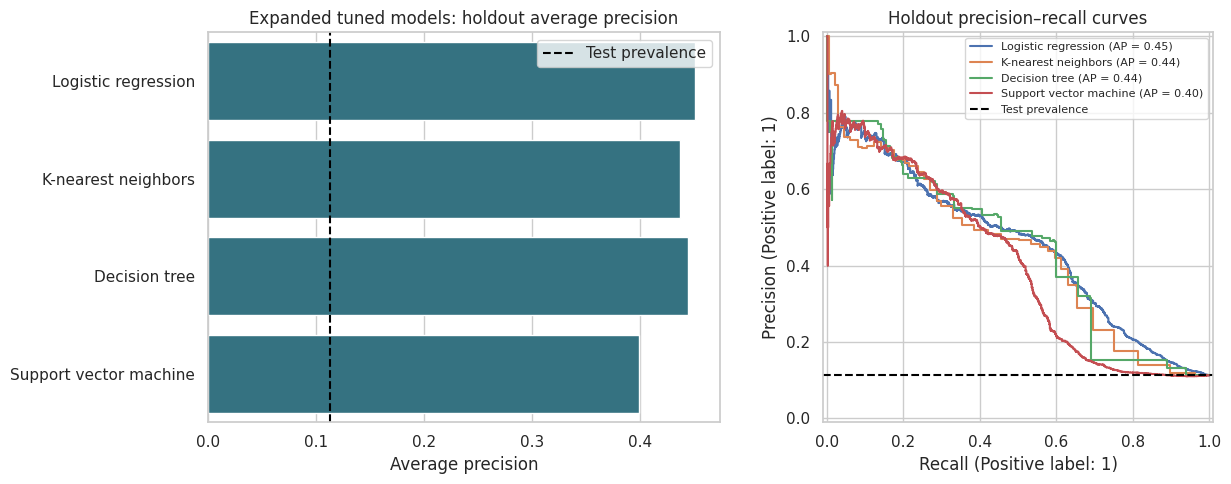

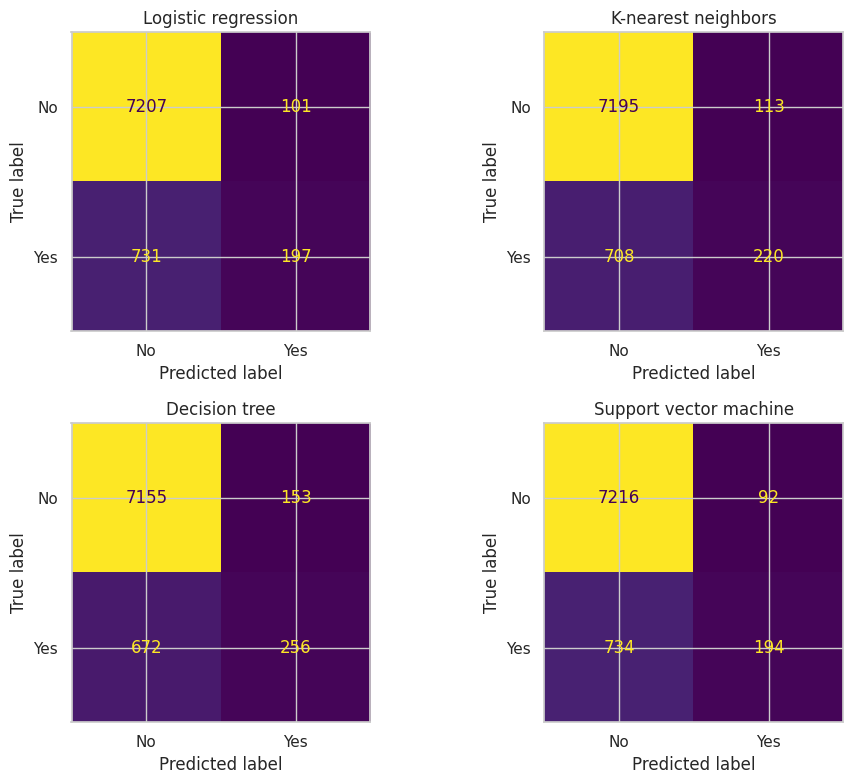

In [15]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
plot_table=tuned_comparison.reset_index()
sns.barplot(data=plot_table,x='average_precision',y='model',ax=axes[0],color='#287a8e')
axes[0].axvline(y_test.mean(),color='black',ls='--',label='Test prevalence')
axes[0].set(title='Expanded tuned models: holdout average precision',xlabel='Average precision',ylabel='')
axes[0].legend()
for name,estimator in tuned_fitted.items():
    PrecisionRecallDisplay.from_predictions(y_test,ranking_score(estimator,X_test),name=name,ax=axes[1])
axes[1].axhline(y_test.mean(),color='black',ls='--',label='Test prevalence')
axes[1].set_title('Holdout precision–recall curves')
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
fig,axes=plt.subplots(2,2,figsize=(10,8))
for ax,(name,estimator) in zip(axes.ravel(),tuned_fitted.items()):
    ConfusionMatrixDisplay.from_estimator(estimator,X_test,y_test,ax=ax,
        display_labels=['No','Yes'],colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()


### Interpreting the logistic coefficients
For logistic regression, a numeric coefficient describes a one-training-standard-deviation increase while holding other encoded features fixed. A dummy-category coefficient is an encoded contribution to log odds. Because all category levels are retained with regularization, individual category odds ratios should not be read as comparisons against a unique omitted reference; differences between two category coefficients are the relevant conditional contrast.

Correlated economic indicators can make individual signs unstable. Coefficients describe fitted associations, not causes. Decision-tree importances are also non-causal; KNN and nonlinear RBF SVM do not provide a comparable coefficient vector.


,coefficient
numeric__emp.var.rate,-2.1756
categorical__month_mar,1.2438
numeric__cons.price.idx,1.1207
categorical__month_jun,-0.7662
categorical__contact_telephone,-0.6538
categorical__month_may,-0.6049
categorical__month_nov,-0.5770
categorical__poutcome_failure,-0.5588
numeric__nr.employed,0.4061
categorical__default_unknown,-0.3861


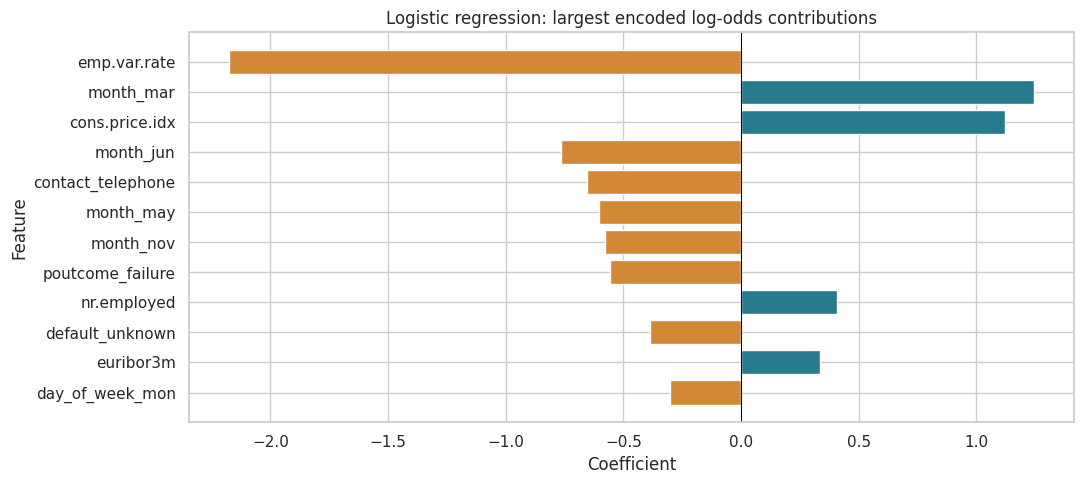

In [16]:
lr=tuned_fitted['Logistic regression']
feature_names=lr.named_steps['preprocess'].get_feature_names_out()
coef=pd.Series(lr.named_steps['model'].coef_[0],index=feature_names,name='coefficient')
top_coef=coef.loc[coef.abs().sort_values(ascending=False).head(12).index]
display(top_coef.round(4).to_frame())
fig,ax=plt.subplots(figsize=(11,5))
labels=[s.replace('numeric__','').replace('categorical__','') for s in top_coef.index]
ax.barh(labels,top_coef.values,color=['#287a8e' if v>0 else '#d38836' for v in top_coef])
ax.invert_yaxis(); ax.axvline(0,color='black',lw=.7)
ax.set(title='Logistic regression: largest encoded log-odds contributions',xlabel='Coefficient',ylabel='Feature')
plt.tight_layout(); plt.show()
coef.to_csv(RESULTS/'logistic_coefficients.csv')


### Holdout uncertainty and calling-budget interpretation
Estimate AP uncertainty for the CV-selected winner with 300 stratified bootstrap resamples of the holdout. This conditional interval holds the fitted model and class counts fixed; it excludes retraining, model-selection uncertainty and campaign/client dependence. It is not a formal test that one algorithm is superior.

The top 20% calculation ranks observed holdout records under a fixed calling budget. It measures historical concentration of subscribers, not the extra subscriptions a new campaign would cause.


In [17]:
winner_scores=ranking_score(winner,X_test)
winner_predictions=winner.predict(X_test)
labels=y_test.to_numpy()
rng=np.random.default_rng(SEED)
positive=np.flatnonzero(labels==1); negative=np.flatnonzero(labels==0)
bootstrap_ap=[]
for _ in range(300):
    sample=np.r_[rng.choice(positive,len(positive),replace=True),rng.choice(negative,len(negative),replace=True)]
    bootstrap_ap.append(average_precision_score(labels[sample],winner_scores[sample]))
ap_interval=np.quantile(bootstrap_ap,[.025,.975])
cm=confusion_matrix(y_test,winner_predictions,labels=[0,1])
top_n=int(np.ceil(.20*len(y_test)))
top_idx=np.argsort(-winner_scores,kind='stable')[:top_n]
top_successes=int(labels[top_idx].sum())
summary={'winner':winner_name,'raw_rows':len(bank_raw),'duplicate_rows_removed':duplicate_count,
    'clean_rows':len(bank),'train_rows':len(y_train),'test_rows':len(y_test),
    'test_positive':int(y_test.sum()),'test_prevalence':float(y_test.mean()),
    'ap_interval_95':ap_interval.tolist(),'confusion_matrix':cm.tolist(),
    'top20_records':top_n,'top20_subscribers':top_successes,
    'top20_capture':top_successes/int(y_test.sum()),
    'top20_precision':top_successes/top_n,'top20_lift':(top_successes/top_n)/y_test.mean(),
    'winner_metrics':tuned_results[winner_name]}
(RESULTS/'summary.json').write_text(json.dumps(summary,indent=2))
print(json.dumps(summary,indent=2))


{
  "winner": "Logistic regression",
  "raw_rows": 41188,
  "duplicate_rows_removed": 12,
  "clean_rows": 41176,
  "train_rows": 32940,
  "test_rows": 8236,
  "test_positive": 928,
  "test_prevalence": 0.11267605633802817,
  "ap_interval_95": [
    0.42055469528439243,
    0.48528931239425965
  ],
  "confusion_matrix": [
    [
      7207,
      101
    ],
    [
      731,
      197
    ]
  ],
  "top20_records": 1648,
  "top20_subscribers": 596,
  "top20_capture": 0.6422413793103449,
  "top20_precision": 0.3616504854368932,
  "top20_lift": 3.2096480582524274,
  "winner_metrics": {
    "fit_seconds": 0.19674260500005403,
    "train_accuracy": 0.9005160898603521,
    "test_accuracy": 0.8989800874210782,
    "balanced_accuracy": 0.5992320060207992,
    "precision": 0.6610738255033557,
    "recall": 0.2122844827586207,
    "f1": 0.32137030995106036,
    "average_precision": 0.45136664587973224,
    "roc_auc": 0.8008644871940056,
    "top20_precision": 0.3616504854368932,
    "top20_lift": 3

## Findings and Recommendations
The following section is generated from this run so that the narrative matches the computed outputs.


In [18]:
m=tuned_results[winner_name]
tn,fp,fn,tp=cm.ravel()
text=f"""### What the results say
- **{winner_name}** was selected by training cross-validation, with mean AP **{m['cv_average_precision']:.3f}** on the shared tuning subset. Its full-training refit achieved holdout AP **{m['average_precision']:.3f}**, compared with prevalence **{y_test.mean():.3f}**; the conditional bootstrap 95% interval is **{ap_interval[0]:.3f}–{ap_interval[1]:.3f}**.
- At its standard decision rule, precision is **{m['precision']:.1%}** and recall is **{m['recall']:.1%}**. It identifies **{tp:,}** subscribers, misses **{fn:,}**, and flags **{fp:,}** non-subscribers. Ranking quality and a useful yes/no cutoff are different questions.
- The highest-ranked **{top_n:,}** records (20% of holdout) contain **{top_successes:,}** subscribers: **{summary['top20_precision']:.1%}** response concentration, **{summary['top20_lift']:.2f}×** the holdout prevalence, capturing **{summary['top20_capture']:.1%}** of observed subscribers. This is a retrospective prioritization result, not a promised campaign conversion rate.
- Client-only default models have limited information. The expanded tuned comparison adds history, economic conditions and planned contact context; changes cannot be credited to hyperparameter tuning alone.
- Prior successful contact is associated with higher subscription rates in training data. This is a candidate for controlled testing, not proof that repeated calls cause subscriptions. Small groups and correlated predictors need cautious interpretation.

### Recommended next steps
1. Pilot a ranked contact list at a defined call budget and compare against the existing campaign policy using a randomized eligible-contact test.
2. Measure net deposit value, agent time, opt-outs and customer burden; choose the cutoff using those costs on validation data rather than optimizing accuracy alone.
3. Obtain timestamps and customer/campaign identifiers for temporal and group-separated validation. Reassess using recent data before deployment; these records are from 2008–2010.
4. Verify planned-contact inputs are available before scoring. Calibrate probabilities if operational decisions require probability estimates.
5. Check stability, subgroup performance, consent and contact-frequency limits before using customer attributes for targeting.

### Limits
No causal effect, profitability, future performance or deployment readiness is established. The fixed random split, historical data, potential repeat contacts, limited tuning grid and 12,000-row tuning subset constrain the comparison. Test-set differences alone do not establish statistical superiority.
"""
display(Markdown(text))
(RESULTS/'findings.md').write_text(text)


Out[0]: 2385


### What the results say
- **Logistic regression** was selected by training cross-validation, with mean AP **0.461** on the shared tuning subset. Its full-training refit achieved holdout AP **0.451**, compared with prevalence **0.113**; the conditional bootstrap 95% interval is **0.421–0.485**.
- At its standard decision rule, precision is **66.1%** and recall is **21.2%**. It identifies **197** subscribers, misses **731**, and flags **101** non-subscribers. Ranking quality and a useful yes/no cutoff are different questions.
- The highest-ranked **1,648** records (20% of holdout) contain **596** subscribers: **36.2%** response concentration, **3.21×** the holdout prevalence, capturing **64.2%** of observed subscribers. This is a retrospective prioritization result, not a promised campaign conversion rate.
- Client-only default models have limited information. The expanded tuned comparison adds history, economic conditions and planned contact context; changes cannot be credited to hyperparameter tuning alone.
- Prior successful contact is associated with higher subscription rates in training data. This is a candidate for controlled testing, not proof that repeated calls cause subscriptions. Small groups and correlated predictors need cautious interpretation.

### Recommended next steps
1. Pilot a ranked contact list at a defined call budget and compare against the existing campaign policy using a randomized eligible-contact test.
2. Measure net deposit value, agent time, opt-outs and customer burden; choose the cutoff using those costs on validation data rather than optimizing accuracy alone.
3. Obtain timestamps and customer/campaign identifiers for temporal and group-separated validation. Reassess using recent data before deployment; these records are from 2008–2010.
4. Verify planned-contact inputs are available before scoring. Calibrate probabilities if operational decisions require probability estimates.
5. Check stability, subgroup performance, consent and contact-frequency limits before using customer attributes for targeting.

### Limits
No causal effect, profitability, future performance or deployment readiness is established. The fixed random split, historical data, potential repeat contacts, limited tuning grid and 12,000-row tuning subset constrain the comparison. Test-set differences alone do not establish statistical superiority.


## Reproducibility and Submission
Run all cells from the directory containing this notebook. Required input: `data/bank-additional-full.csv`. The data dictionary and supplied PDF are included for context. Raw duration remains in the CSV for provenance but is never a model input. Results CSVs and the summary JSON are regenerated on every complete run; saved notebook outputs allow review without rerunning.

The train/test seed, CV seed and bootstrap seed are fixed at 42. Grid search uses one worker to keep memory use predictable; total runtime depends on the machine. A full-training grid or temporal evaluation is a future extension, not silently substituted here.

See [README](README.md) for the nontechnical report and [requirements](requirements.txt) for the environment used. The supplied 10% CSV and empty prompt notebook are omitted from the submission folder to avoid duplicate inputs and unnecessary files.
